<a href="https://colab.research.google.com/github/nevita275/ML_20_Nevita/blob/main/JS07/JS07-Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20

# TUGAS

## Upload dan Import Library

In [1]:
from google.colab import files
uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

In [3]:
df = pd.read_csv('CC_Customer_Dataset.csv')

## 1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

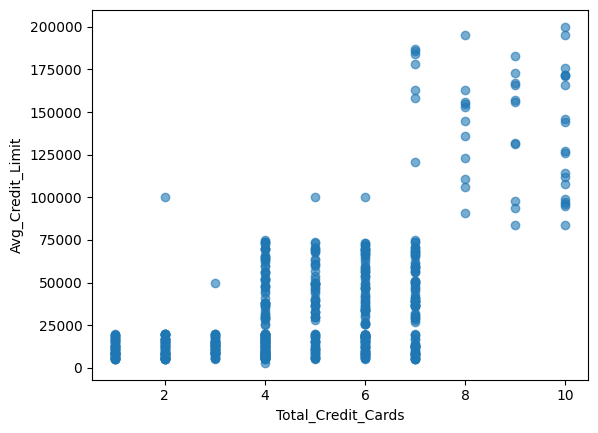

                    Avg_Credit_Limit  Total_Credit_Cards
Avg_Credit_Limit             1.00000             0.60886
Total_Credit_Cards           0.60886             1.00000


In [4]:
plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], alpha=.6)
plt.xlabel('Total_Credit_Cards'); plt.ylabel('Avg_Credit_Limit')
plt.show()
print(df[['Avg_Credit_Limit','Total_Credit_Cards']].corr())

**Analisis:**
Sebaran data **tidak dapat dikatakan linier**. Nilai korelasi Pearson antara
Avg_Credit_Limit dan Total_Credit_Cards sebesar 0,61, yang hanya menunjukkan
hubungan positif sedang, bukan hubungan linier yang kuat. Pada scatterplot,
titik-titik tidak membentuk garis lurus, melainkan terkumpul dalam beberapa
kelompok: nasabah dengan 1-3 kartu memiliki limit rendah (di bawah sekitar
20.000), nasabah dengan 4-7 kartu memiliki limit yang menyebar lebar (sekitar
3.000-75.000), dan nasabah dengan 8-10 kartu memiliki limit sangat tinggi
(sekitar 85.000-200.000). Karena pola datanya berbentuk kelompok, data ini
lebih tepat dianalisis dengan klasterisasi.

## 2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

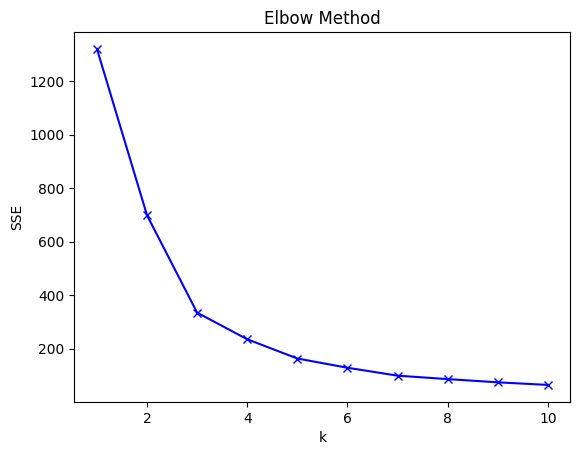

In [5]:
X2 = df[['Avg_Credit_Limit','Total_Credit_Cards']]
scaler = StandardScaler()
Xs2 = scaler.fit_transform(X2)
sse = []
for k in range(1, 11):
    sse.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs2).inertia_)
plt.plot(range(1, 11), sse, 'bx-')
plt.xlabel('k'); plt.ylabel('SSE'); plt.title('Elbow Method')
plt.show()

**Analisis:**
Nilai SSE untuk k=1 sampai k=5 berturut-turut adalah 1320, 698, 335, 235, dan
164. Penurunan SSE dari k=2 ke k=3 masih besar (sekitar 363), tetapi dari k=3
ke k=4 penurunannya jauh lebih kecil (sekitar 100) dan selanjutnya cenderung
landai. Titik tempat penurunan berubah dari tajam menjadi landai (titik
"elbow") berada di **k = 3**, sehingga k=3 dipilih sebagai jumlah cluster
terbaik. Pemilihan ini juga sesuai dengan scatterplot pada soal 1 yang
menunjukkan tiga kelompok nasabah. Nilai k yang lebih besar tidak dipilih
karena SSE pasti terus mengecil seiring bertambahnya cluster, tetapi
perbaikannya tidak signifikan dan cluster menjadi terlalu kecil.

## 3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

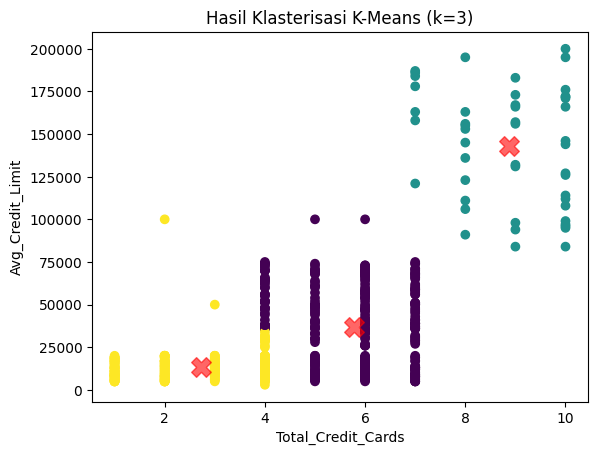

0    330
1     48
2    282
Name: count, dtype: int64
         Avg_Credit_Limit  Total_Credit_Cards
cluster                                      
0            37160.606061            5.787879
1           142750.000000            8.875000
2            13134.751773            2.730496


In [11]:
# K-Means k=3
km = KMeans(n_clusters=3, n_init=10, random_state=42)
y = km.fit_predict(Xs2)
cent = scaler.inverse_transform(km.cluster_centers_)

plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], c=y)
plt.scatter(cent[:, 1], cent[:, 0], c='red', s=200, alpha=.6, marker='X')
plt.xlabel('Total_Credit_Cards'); plt.ylabel('Avg_Credit_Limit')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()

# Jumlah anggota dan rata-rata tiap cluster
print(pd.Series(y).value_counts().sort_index())
print(pd.DataFrame(X2).assign(cluster=y).groupby('cluster').mean())

**Interpretasi cluster (k=3):**
- Cluster 2 (282 nasabah): rata-rata limit sekitar 13.135 dengan sekitar 2,7
  kartu, yaitu nasabah dengan limit rendah dan kartu sedikit.
- Cluster 0 (330 nasabah): rata-rata limit sekitar 37.161 dengan sekitar 5,8
  kartu, yaitu nasabah menengah.
- Cluster 1 (48 nasabah): rata-rata limit sekitar 142.750 dengan sekitar 8,9
  kartu, yaitu nasabah premium dengan limit tinggi dan kartu banyak.

## 4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

In [7]:
feat = ['Avg_Credit_Limit','Total_Credit_Cards','Total_visits_bank',
        'Total_visits_online','Total_calls_made']
Xs = StandardScaler().fit_transform(df[feat])
min_samples = 10

## 5. Tentukan jumlah k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

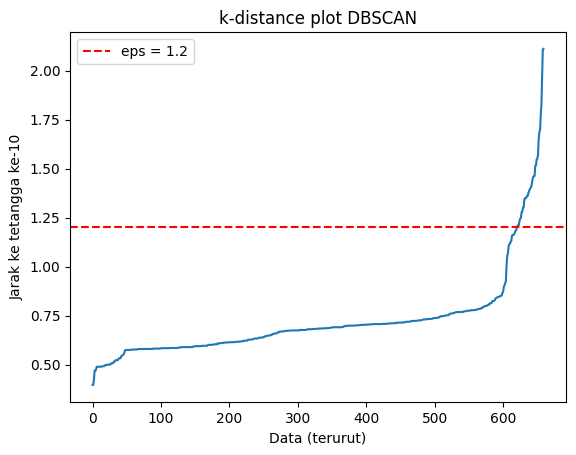

In [8]:
d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xs).kneighbors(Xs)
plt.plot(np.sort(d[:, -1]))
plt.axhline(1.2, color='r', ls='--', label='eps = 1.2')
plt.xlabel('Data (terurut)')
plt.ylabel('Jarak ke tetangga ke-10')
plt.title('k-distance plot DBSCAN')
plt.legend()
plt.show()

In [12]:
labels = DBSCAN(eps=1.2, min_samples=min_samples).fit_predict(Xs)
print('Cluster:', set(labels), '| Noise:', (labels == -1).sum())

# Jumlah anggota tiap cluster (-1 = noise)
print(pd.Series(labels).value_counts().sort_index())

Cluster: {np.int64(0), np.int64(1), np.int64(-1)} | Noise: 13
-1     13
 0    608
 1     39
Name: count, dtype: int64


**Analisis:**
Pada DBSCAN, parameter yang ditentukan dengan elbow method adalah nilai
**eps**, menggunakan k-distance plot dengan min_samples = 10 (2 x jumlah fitur,
yaitu 5 fitur). Grafik menunjukkan kurva yang datar sekitar 0,7-0,85 untuk
sebagian besar data, lalu naik tajam mulai sekitar 1,2. Titik siku ini dipilih
sebagai **eps = 1,2**. Nilai eps yang lebih kecil (misalnya 0,8) membuat terlalu
banyak data menjadi noise (54 data) dan hanya menghasilkan satu cluster,
sedangkan nilai yang lebih besar akan menyatukan hampir semua data ke dalam
satu cluster. Dengan eps = 1,2 diperoleh 2 cluster (608 dan 39 data) dan
13 data noise.

## 6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

In [10]:
m = labels != -1
print('Silhouette:', silhouette_score(Xs[m], labels[m]))
print('DBI       :', davies_bouldin_score(Xs[m], labels[m]))

Silhouette: 0.5685985141804305
DBI       : 0.6073750936839484


**Analisis:**
Evaluasi dihitung tanpa titik noise (label -1) karena noise bukan bagian dari
cluster. Diperoleh Silhouette Score sekitar 0,569 dan Davies-Bouldin Index
(DBI) sekitar 0,607. Silhouette Score yang mendekati 1 menunjukkan data berada
di cluster yang tepat dan antar cluster terpisah cukup baik, sedangkan DBI yang
semakin kecil menunjukkan kualitas cluster yang semakin baik (cluster padat dan
saling berjauhan). Jadi model DBSCAN ini tergolong baik. Namun, DBSCAN hanya
menemukan 2 cluster, lebih sedikit dari K-Means (3 cluster), karena DBSCAN
menganggap nasabah limit rendah dan menengah sebagai satu wilayah padat yang
saling bersambung.